In [11]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import HTML, display
from base64 import b64encode

print("OpenCV Version:", cv2.__version__)
print("Libraries Loaded Successfully")

OpenCV Version: 5.0.0
Libraries Loaded Successfully


In [3]:
os.makedirs('videos', exist_ok=True)

print("Please Upload A Video File:")
uploaded = files.upload()

for filename in uploaded.keys():
    dest = os.path.join('videos', filename)
    os.rename(filename, dest)
    print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Videos Folder:")
print(os.listdir('videos'))

Please Upload A Video File:


Saving slow_traffic_small.mp4 to slow_traffic_small.mp4
File 'slow_traffic_small.mp4' Moved To 'videos/slow_traffic_small.mp4'.

Contents Of Videos Folder:
['slow_traffic_small.mp4']


In [4]:
def drawRectangle(frame, bbox):
    p1 = (int(bbox[0]), int(bbox[1]))
    p2 = (int(bbox[0] + bbox[2]), int(bbox[1] + bbox[3]))
    cv2.rectangle(frame, p1, p2, (255, 0, 0), 2, 1)

def displayRectangle(frame, bbox):
    plt.figure(figsize=(20, 10))
    frameCopy = frame.copy()
    drawRectangle(frameCopy, bbox)
    frameCopy = cv2.cvtColor(frameCopy, cv2.COLOR_BGR2RGB)
    plt.imshow(frameCopy)
    plt.axis('off')
    plt.show()

In [6]:
video_files = [f for f in os.listdir('videos') if f.lower().endswith(('.mp4', '.avi', '.mov'))]
video_input_file_name = os.path.join('videos', video_files[0])
print("Using Video:", video_input_file_name)

video = cv2.VideoCapture(video_input_file_name)
ok, frame = video.read()

if not video.isOpened():
    print("Could Not Open Video")
else:
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    print(f"Video Resolution: {width}x{height}")

video_output_file_name = 'output-TemplateTracking.mp4'
video_out = cv2.VideoWriter(video_output_file_name, cv2.VideoWriter_fourcc(*'mp4v'), 10, (width, height))

Using Video: videos/slow_traffic_small.mp4
Video Resolution: 640x360


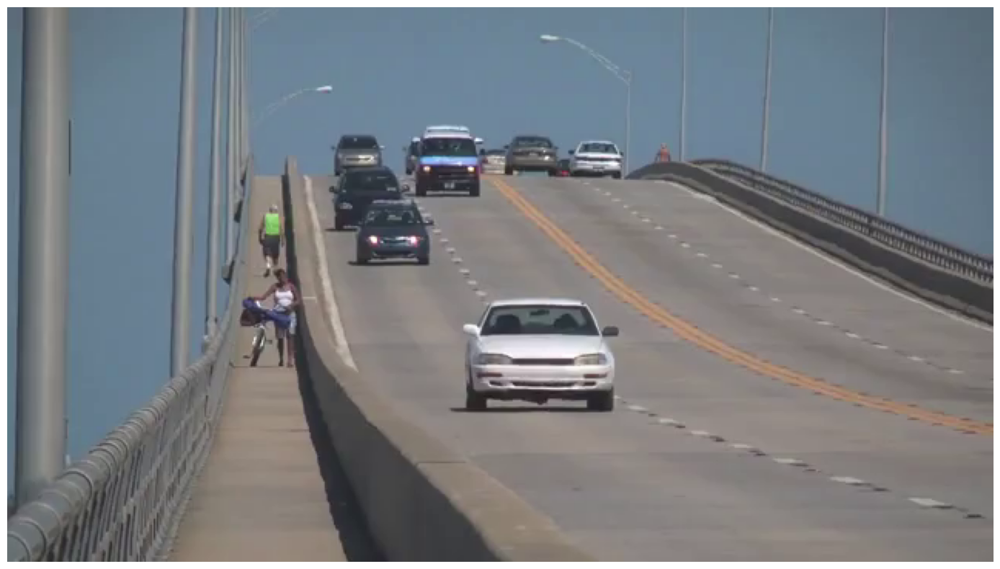

Bounding Box: (1300, 405, 160, 120)


In [8]:
bbox = (1300, 405, 160, 120)

displayRectangle(frame, bbox)
print("Bounding Box:", bbox)

Starting Tracking...
Tracking Done. Showing 12 sample frames.


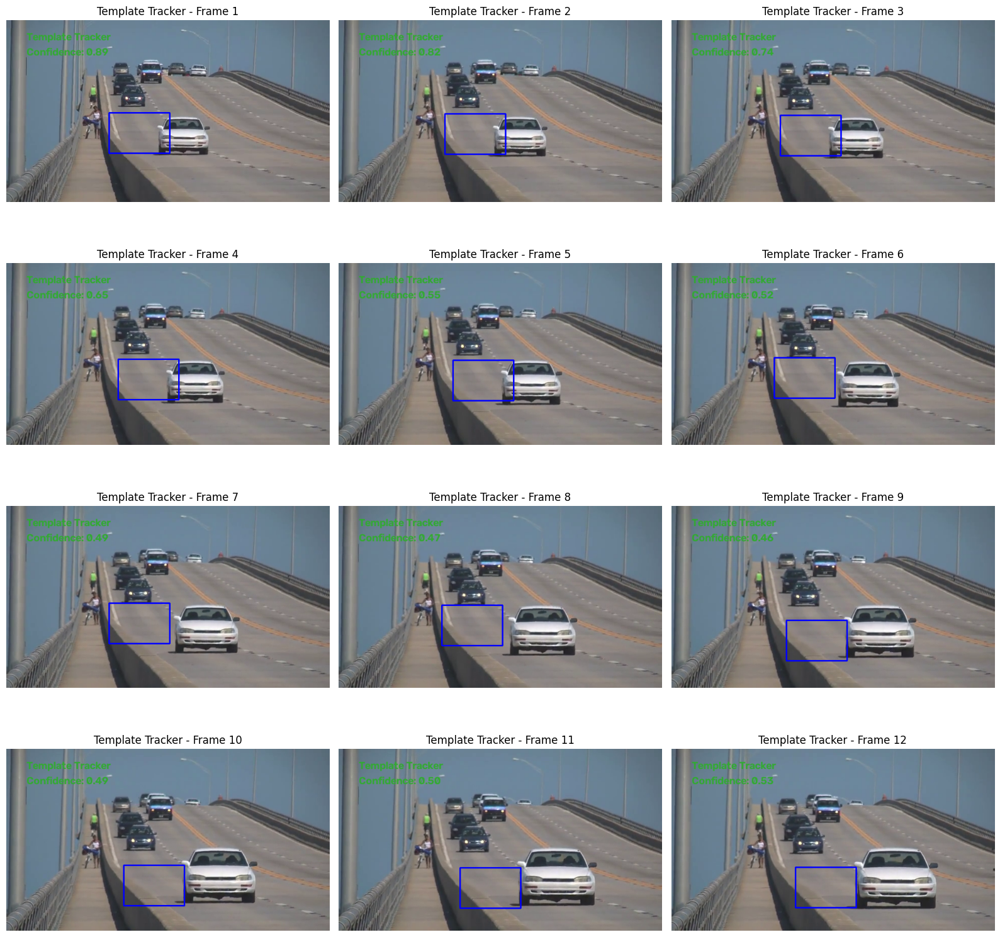

In [10]:
video = cv2.VideoCapture(video_input_file_name)
ok, frame = video.read()


bbox = (200, 180, 120, 80)

x, y, w, h = bbox
h_max, w_max, _ = frame.shape
x = max(0, min(x, w_max - 1))
y = max(0, min(y, h_max - 1))
w = min(w, w_max - x)
h = min(h, h_max - y)

template = frame[y:y+h, x:x+w]
if template.size == 0:
    raise ValueError(f"Cropped Template Is Empty! Frame Size: {frame.shape}, bbox Requested: {bbox}")

template_gray = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)

frames_to_show = []
max_show = 12
frame_count = 0

print("Starting Tracking...")

video_out = cv2.VideoWriter(video_output_file_name, cv2.VideoWriter_fourcc(*'mp4v'), 10, (width, height))

while True:
    ok, frame = video.read()
    if not ok:
        break

    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    res = cv2.matchTemplate(frame_gray, template_gray, cv2.TM_CCOEFF_NORMED)
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

    top_left = max_loc
    new_bbox = (top_left[0], top_left[1], w, h)

    drawRectangle(frame, new_bbox)

    cv2.putText(frame, "Template Tracker", (40, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (50, 170, 50), 2)
    cv2.putText(frame, f"Confidence: {max_val:.2f}", (40, 70),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (50, 170, 50), 2)

    video_out.write(frame)

    frame_count += 1
    if frame_count % 8 == 0 and len(frames_to_show) < max_show:
        frames_to_show.append(frame.copy())

video.release()
video_out.release()
print(f"Tracking Done. Showing {len(frames_to_show)} sample frames.")

n = len(frames_to_show)
if n > 0:
    plt.figure(figsize=[16, 4 * ((n + 2) // 3)])
    for i in range(n):
        plt.subplot((n + 2) // 3, 3, i + 1)
        plt.imshow(cv2.cvtColor(frames_to_show[i], cv2.COLOR_BGR2RGB))
        plt.title(f"Template Tracker - Frame {i+1}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

In [12]:
output_file = video_output_file_name
if os.path.exists(output_file):
    mp4 = open(output_file, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    display(HTML(f"""
    <video width=1024 controls>
      <source src="{data_url}" type="video/mp4">
    </video>
    """))
else:
    print(f"Output Video Not Found: {output_file}")